# GlycoVote — previsão de diabetes com Soft Voting

AV2 – Machine Learning 2

Alunos: Davi Melo, Elizabete Barbosa, Ivan Edward

Base: Diabetes Health Indicators (BRFSS 2015, Kaggle), versão balanceada 50/50.

O notebook tem duas partes:
1. o **baseline**, que é exatamente a solução que a gente propôs (step 1, 2 e 3)
2. as **melhorias** que testamos em cima dele, comparando sempre com o baseline

Resumo da proposta:
- step 1: definir o alvo, olhar nulos, duplicados, correlação e influência sobre o alvo, escolher as features e separar 80/20 estratificado
- step 2: regressão logística, random forest e XGBoost (no lugar do gradient boosting)
- step 3: soft voting → média das 3 probabilidades, se >= limiar (0.5) é 1, senão é 0
- os modelos rodam em paralelo e sem otimização de hiperparâmetros

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from joblib import Parallel, delayed
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
LIMIAR = 0.5
FIG = '../reports/figures'
os.makedirs(FIG, exist_ok=True)

## Parte 1 - Baseline

### Step 1: dados e análise exploratória

In [2]:
path = kagglehub.dataset_download('alexteboul/diabetes-health-indicators-dataset')
df = pd.read_csv(path + '/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')

# alvo: Diabetes_binary (0 = não tem, 1 = pré-diabetes ou diabetes)
ALVO = 'Diabetes_binary'
print(df.shape)
df.head()

(70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [3]:
df[ALVO].value_counts(normalize=True)

Diabetes_binary
0.0    0.5
1.0    0.5
Name: proportion, dtype: float64

Nulos e duplicados:

In [4]:
print('nulos:', df.isna().sum().sum())
print('duplicados:', df.duplicated().sum())

# tirando os duplicados antes do split, senão a mesma linha pode cair no treino e no teste
df = df.drop_duplicates().reset_index(drop=True)
df.shape

nulos: 0
duplicados: 1635


(69057, 22)

Matriz de correlação:

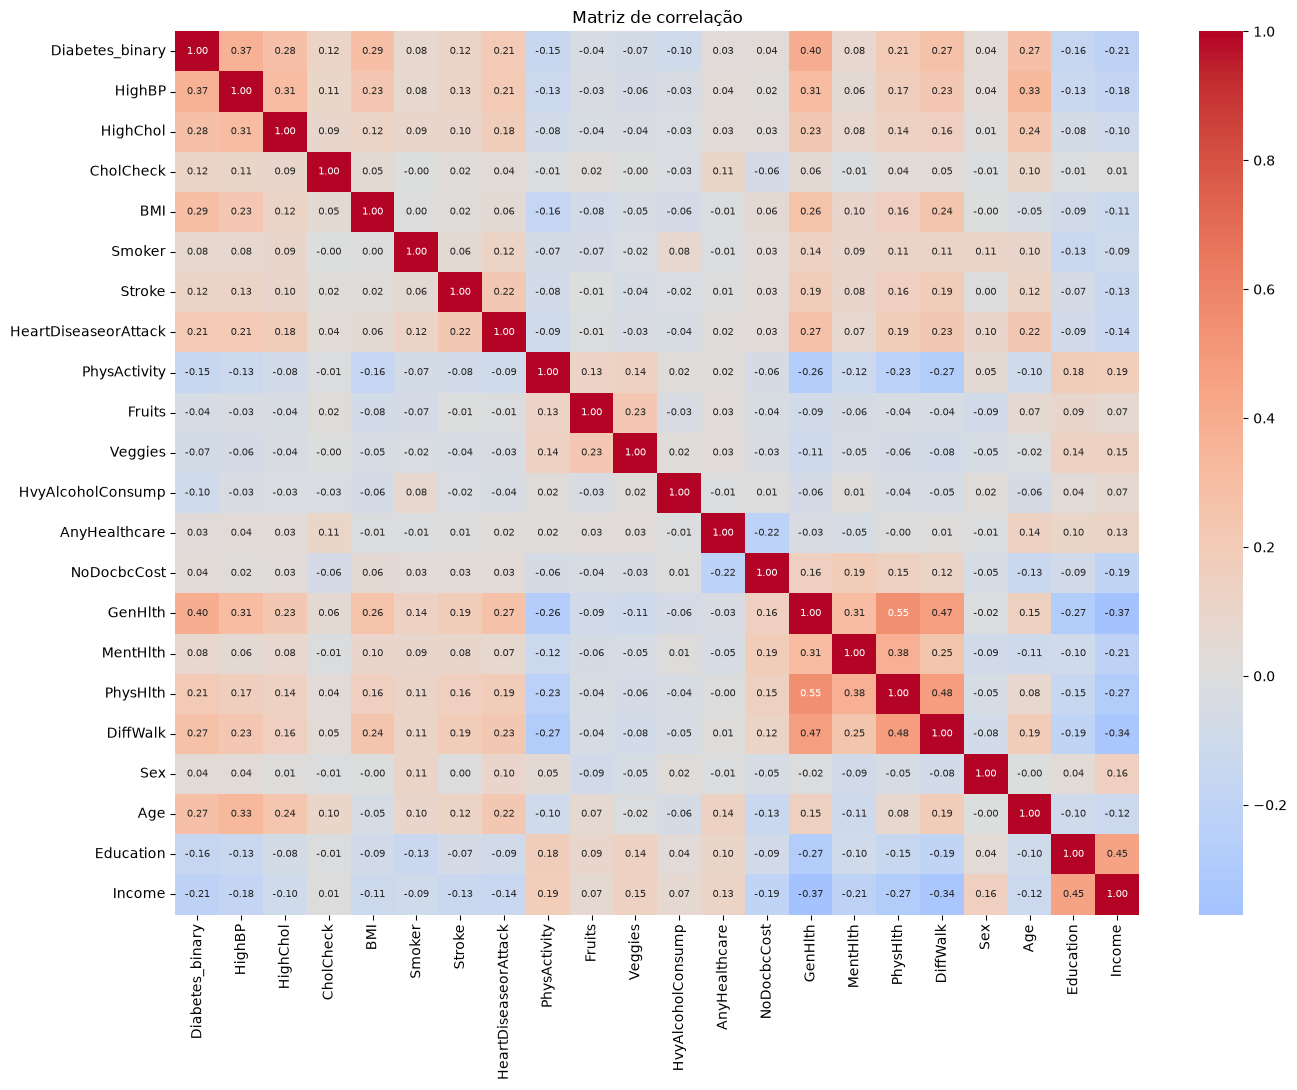

In [5]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Matriz de correlação')
plt.tight_layout()
plt.show()

In [6]:
# pares de features mais correlacionados entre si (multicolinearidade)
c = df.drop(columns=ALVO).corr().abs()
c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().sort_values(ascending=False).head(8)

GenHlth    PhysHlth    0.550138
PhysHlth   DiffWalk    0.484092
GenHlth    DiffWalk    0.472338
Education  Income      0.450376
MentHlth   PhysHlth    0.376625
GenHlth    Income      0.370204
DiffWalk   Income      0.335819
HighBP     Age         0.333721
dtype: float64

O maior par é GenHlth x PhysHlth (~0.55). Nada perto de 0.8, então não precisa tirar variável por multicolinearidade.

Divisão 80/20 estratificada:

In [7]:
X = df.drop(columns=ALVO)
y = df[ALVO].astype(int)

X_train_all, X_test_all, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('treino:', X_train_all.shape, ' teste:', X_test_all.shape)
print('% classe 1 treino/teste:', round(y_train.mean(), 3), round(y_test.mean(), 3))

treino: (55245, 21)  teste: (13812, 21)
% classe 1 treino/teste: 0.508 0.508


Influência sobre o alvo e escolha das features. Usamos a correlação (em módulo) de cada feature com o alvo,
calculada **só no treino**, e ficamos com as que têm |r| >= 0.05.

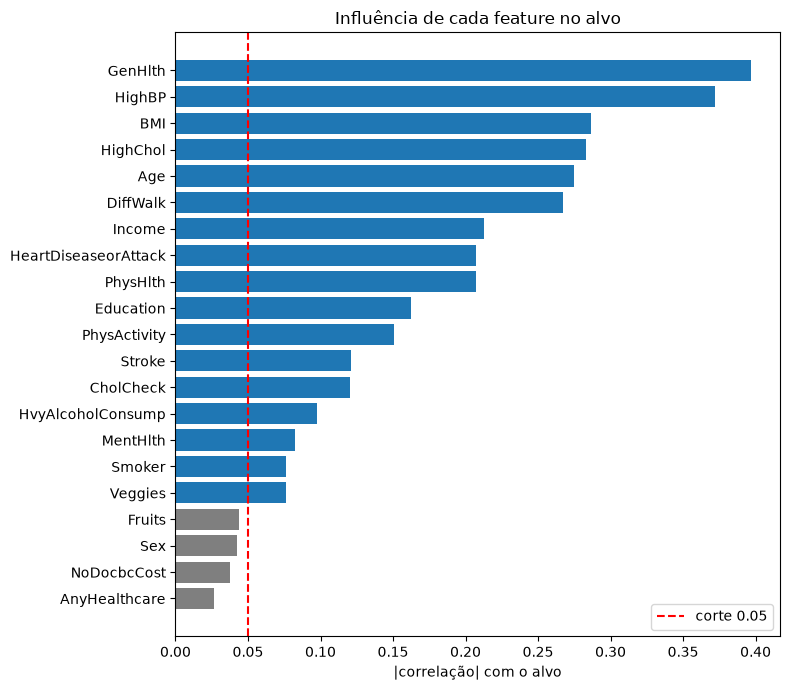

17 features: ['GenHlth', 'HighBP', 'BMI', 'HighChol', 'Age', 'DiffWalk', 'Income', 'HeartDiseaseorAttack', 'PhysHlth', 'Education', 'PhysActivity', 'Stroke', 'CholCheck', 'HvyAlcoholConsump', 'MentHlth', 'Smoker', 'Veggies']
saíram: ['Fruits', 'Sex', 'NoDocbcCost', 'AnyHealthcare']


In [8]:
CORTE = 0.05
infl = pd.concat([X_train_all, y_train], axis=1).corr()[ALVO].drop(ALVO).abs().sort_values(ascending=False)

plt.figure(figsize=(8, 7))
plt.barh(infl.index[::-1], infl.values[::-1], color=['tab:blue' if v >= CORTE else 'tab:gray' for v in infl.values[::-1]])
plt.axvline(CORTE, color='red', ls='--', label='corte 0.05')
plt.xlabel('|correlação| com o alvo')
plt.title('Influência de cada feature no alvo')
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIG}/influencia_features.png', dpi=120)
plt.show()

FEATURES = infl[infl >= CORTE].index.tolist()
print(len(FEATURES), 'features:', FEATURES)
print('saíram:', infl[infl < CORTE].index.tolist())

X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

### Step 2: os 3 modelos (default)

A regressão logística vai com StandardScaler porque é sensível a escala (e max_iter maior só pra convergir).
Os três são treinados em paralelo com joblib.

In [9]:
modelos = {
    'Regressão Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    'Random Forest': RandomForestClassifier(random_state=SEED, n_jobs=1),
    'XGBoost': XGBClassifier(random_state=SEED, n_jobs=1),
}

def treinar(nome, modelo, X_, y_):
    return nome, modelo.fit(X_, y_)

modelos = dict(Parallel(n_jobs=3)(delayed(treinar)(n, m, X_train, y_train) for n, m in modelos.items()))
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}

### Step 3: soft voting

Média das 3 probabilidades, >= 0.5 vira 1.

In [10]:
def soft_voting(lista_probas, limiar=LIMIAR, pesos=None):
    media = np.average(np.column_stack(lista_probas), axis=1, weights=pesos)
    return media, (media >= limiar).astype(int)

def metricas(y_true, proba, limiar=LIMIAR):
    pred = (proba >= limiar).astype(int)
    return {'Acurácia': accuracy_score(y_true, pred), 'Precisão': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred), 'ROC-AUC': roc_auc_score(y_true, proba)}

probas['Soft Voting (baseline)'], pred_base = soft_voting([probas[n] for n in modelos])

pd.DataFrame({n: metricas(y_test, p) for n, p in probas.items()}).T.round(4)

,Acurácia,Precisão,Recall,F1,ROC-AUC
Regressão Logística,0.7439,0.7374,0.7705,0.7536,0.8163
Random Forest,0.7235,0.7071,0.7783,0.7410,0.7895
XGBoost,0.7415,0.7269,0.7872,0.7558,0.8130
Soft Voting (baseline),0.7401,0.7265,0.7836,0.7540,0.8160


              precision    recall  f1-score   support

           0     0.7566    0.6951    0.7245      6792
           1     0.7265    0.7836    0.7540      7020

    accuracy                         0.7401     13812
   macro avg     0.7415    0.7394    0.7392     13812
weighted avg     0.7413    0.7401    0.7395     13812



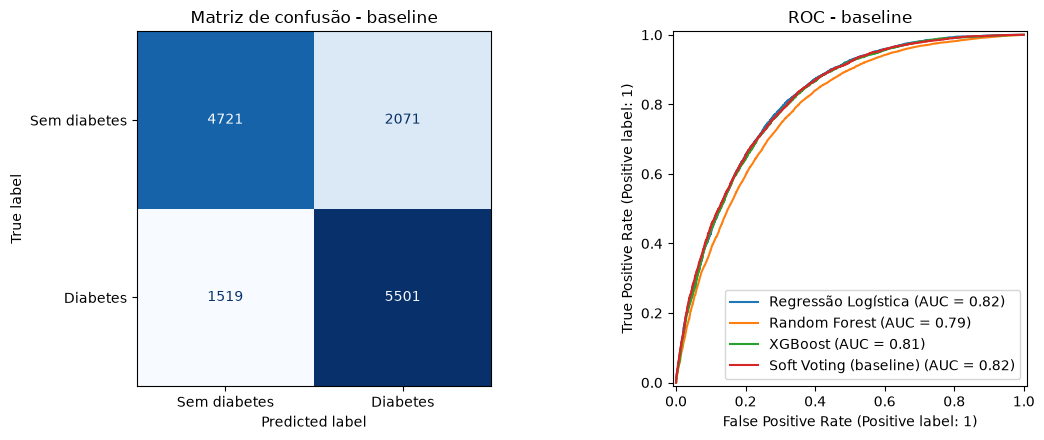

In [11]:
print(classification_report(y_test, pred_base, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_base), display_labels=['Sem diabetes', 'Diabetes']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Matriz de confusão - baseline')
for n, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=n, ax=ax[1])
ax[1].set_title('ROC - baseline')
plt.tight_layout()
plt.savefig(f'{FIG}/baseline_confusao_roc.png', dpi=120)
plt.show()

### Resultado do baseline

**Soft voting: acurácia 0.7401 | ROC-AUC 0.8160** (precisão 0.7265, recall 0.7836, F1 0.7540), no teste com 13.812 linhas.

Observações:
- o ensemble ficou **pior que a regressão logística sozinha** (0.7439 / 0.8163). Quem puxa pra baixo é a random forest
  default (0.7235 / 0.7895): as árvores crescem sem limite, decoram o treino, e na média simples ela pesa igual aos outros dois
- erra mais com falso positivo do que com falso negativo (recall > precisão), o que pra triagem até é o lado menos ruim
- o exemplo do professor deu 0.7536 com LightGBM, mas com split 70/30 e sem tirar duplicados, então não dá pra comparar direto

## Parte 2 - Melhorias

Regras pra comparação ficar justa:
- mesmo split do baseline
- toda decisão (hiperparâmetro, features, pesos, limiar) é tomada com **validação cruzada de 5 folds no treino**; o teste só serve pra medir
- as melhorias vão se somando (M2 já tem o M1, etc.), pra ver quanto cada uma acrescenta

O que testamos:
- **M1** otimizar hiperparâmetros com Optuna (a RF default claramente tá com overfitting)
- **M2** one-hot nas variáveis ordinais pra regressão logística + testar se o corte de features ajudou mesmo
- **M3** pesos diferentes pra cada modelo no voting
- **M4** ajustar o limiar em vez de usar 0.5
- e como alternativa, **stacking** com regressão logística em cima dos 3 modelos

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_auc(modelo, X_):
    return cross_val_score(modelo, X_, y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()

def oof_proba(modelo, X_):
    # probabilidade out-of-fold: cada linha do treino é prevista por um modelo que não viu ela
    return cross_val_predict(modelo, X_, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

historico = {'Baseline': metricas(y_test, probas['Soft Voting (baseline)'])}

### M1 - otimização de hiperparâmetros (Optuna, 5-fold, ROC-AUC)

In [13]:
def otimizar(construtor, espaco, X_, n_trials):
    estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    estudo.optimize(lambda t: cv_auc(construtor(espaco(t)), X_), n_trials=n_trials)
    return estudo.best_params, estudo.best_value

esp_lr = lambda t: {'C': t.suggest_float('C', 1e-3, 10, log=True)}
esp_rf = lambda t: {
    'n_estimators': 300,
    'max_depth': t.suggest_int('max_depth', 6, 30),
    'min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 50),
    'max_features': t.suggest_float('max_features', 0.2, 0.8),
}
esp_xgb = lambda t: {
    'n_estimators': t.suggest_int('n_estimators', 200, 800),
    'learning_rate': t.suggest_float('learning_rate', 0.01, 0.2, log=True),
    'max_depth': t.suggest_int('max_depth', 2, 8),
    'min_child_weight': t.suggest_int('min_child_weight', 1, 20),
    'subsample': t.suggest_float('subsample', 0.6, 1.0),
    'colsample_bytree': t.suggest_float('colsample_bytree', 0.5, 1.0),
    'reg_lambda': t.suggest_float('reg_lambda', 1e-3, 10, log=True),
}

mk_lr = lambda p: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED, **p))
mk_rf = lambda p: RandomForestClassifier(random_state=SEED, n_jobs=1, **p)
mk_xgb = lambda p: XGBClassifier(random_state=SEED, n_jobs=1, **p)

print('CV AUC default:', {k: round(v, 4) for k, v in
      {'LR': cv_auc(mk_lr({}), X_train), 'RF': cv_auc(mk_rf({}), X_train), 'XGB': cv_auc(mk_xgb({}), X_train)}.items()})

# demora uns minutos
best_lr, auc_lr = otimizar(mk_lr, esp_lr, X_train, 10)
best_rf, auc_rf = otimizar(mk_rf, esp_rf, X_train, 15)
best_xgb, auc_xgb = otimizar(mk_xgb, esp_xgb, X_train, 30)
best_rf['n_estimators'] = 300

print('CV AUC otimizado:', {'LR': round(auc_lr, 4), 'RF': round(auc_rf, 4), 'XGB': round(auc_xgb, 4)})
print('LR :', best_lr)
print('RF :', best_rf)
print('XGB:', best_xgb)

CV AUC default: {'LR': np.float64(0.8191), 'RF': np.float64(0.7928), 'XGB': np.float64(0.8167)}


CV AUC otimizado: {'LR': 0.8191, 'RF': 0.822, 'XGB': 0.8258}
LR : {'C': 0.03148911647956861}
RF : {'max_depth': 9, 'min_samples_leaf': 2, 'max_features': 0.283015560452028, 'n_estimators': 300}
XGB: {'n_estimators': 750, 'learning_rate': 0.012500244652865334, 'max_depth': 5, 'min_child_weight': 3, 'subsample': 0.6590810599946814, 'colsample_bytree': 0.6291994994944616, 'reg_lambda': 4.123230599861979}


In [14]:
m1 = {'LR': mk_lr(best_lr), 'RF': mk_rf(best_rf), 'XGB': mk_xgb(best_xgb)}
for m in m1.values():
    m.fit(X_train, y_train)
p1 = {k: m.predict_proba(X_test)[:, 1] for k, m in m1.items()}
p1['Soft Voting'], _ = soft_voting(list(p1.values()))
historico['M1 - hiperparâmetros'] = metricas(y_test, p1['Soft Voting'])
pd.DataFrame({k: metricas(y_test, p) for k, p in p1.items()}).T.round(4)

,Acurácia,Precisão,Recall,F1,ROC-AUC
LR,0.7441,0.7376,0.7708,0.7538,0.8163
RF,0.7438,0.7262,0.7962,0.7596,0.8189
XGB,0.7463,0.7299,0.7952,0.7611,0.8230
Soft Voting,0.7463,0.7310,0.7925,0.7605,0.8219


### M2 - features pra regressão logística

RF e XGB já pegam relação não linear sozinhos, a regressão logística não. Ela trata Age (13 faixas), GenHlth (1 a 5),
Education e Income como se cada degrau tivesse o mesmo efeito. Com one-hot ela aprende um efeito por faixa.
Aproveitamos pra ver se o corte de |r| >= 0.05 do baseline ajudou ou atrapalhou.

In [15]:
ORDINAIS = ['GenHlth', 'Age', 'Education', 'Income']
TODAS = X_train_all.columns.tolist()

def mk_lr_oh(p, cols):
    cat = [c for c in ORDINAIS if c in cols]
    num = [c for c in cols if c not in cat]
    prep = make_column_transformer((OneHotEncoder(handle_unknown='ignore'), cat), (StandardScaler(), num))
    return make_pipeline(prep, LogisticRegression(max_iter=3000, random_state=SEED, **p))

comp = {
    'LR atual (selecionadas)': cv_auc(mk_lr(best_lr), X_train),
    'LR one-hot (selecionadas)': cv_auc(mk_lr_oh(best_lr, FEATURES), X_train),
    'LR one-hot (todas)': cv_auc(mk_lr_oh(best_lr, TODAS), X_train_all),
    'XGB (selecionadas)': cv_auc(m1['XGB'], X_train),
    'XGB (todas)': cv_auc(mk_xgb(best_xgb), X_train_all),
    'RF (selecionadas)': cv_auc(m1['RF'], X_train),
    'RF (todas)': cv_auc(mk_rf(best_rf), X_train_all),
}
pd.Series(comp, name='CV AUC').round(4)

LR atual (selecionadas)      0.8191
LR one-hot (selecionadas)    0.8209
LR one-hot (todas)           0.8218
XGB (selecionadas)           0.8258
XGB (todas)                  0.8270
RF (selecionadas)            0.8220
RF (todas)                   0.8226
Name: CV AUC, dtype: float64

In [16]:
# fica com todas as features se a média dos 3 modelos na CV for melhor
media_sel = np.mean([comp['LR one-hot (selecionadas)'], comp['XGB (selecionadas)'], comp['RF (selecionadas)']])
media_all = np.mean([comp['LR one-hot (todas)'], comp['XGB (todas)'], comp['RF (todas)']])
COLS = TODAS if media_all > media_sel else FEATURES
print(f'selecionadas {media_sel:.4f} x todas {media_all:.4f} -> usando {len(COLS)} features')

Xtr2, Xte2 = X_train_all[COLS], X_test_all[COLS]
m2 = {'LR': mk_lr_oh(best_lr, COLS), 'RF': mk_rf(best_rf), 'XGB': mk_xgb(best_xgb)}
for m in m2.values():
    m.fit(Xtr2, y_train)
p2 = {k: m.predict_proba(Xte2)[:, 1] for k, m in m2.items()}
p2['Soft Voting'], _ = soft_voting(list(p2.values()))
historico['M2 - + features LR'] = metricas(y_test, p2['Soft Voting'])
pd.DataFrame({k: metricas(y_test, p) for k, p in p2.items()}).T.round(4)

selecionadas 0.8229 x todas 0.8238 -> usando 21 features


,Acurácia,Precisão,Recall,F1,ROC-AUC
LR,0.7454,0.7355,0.7792,0.7567,0.8196
RF,0.7464,0.7284,0.7989,0.7620,0.8196
XGB,0.7496,0.7322,0.8000,0.7646,0.8250
Soft Voting,0.7499,0.7349,0.7947,0.7636,0.8235


### M3 - pesos no soft voting

Pega as probabilidades out-of-fold de cada modelo e testa uma grade de pesos (passo 0.05, somando 1),
ficando com o que dá maior AUC.

In [17]:
oof = {k: oof_proba(m, Xtr2) for k, m in m2.items()}
O = np.column_stack([oof['LR'], oof['RF'], oof['XGB']])

grade = [(a, b, round(1 - a - b, 2)) for a in np.arange(0, 1.01, 0.05) for b in np.arange(0, 1.01 - a, 0.05)]
auc_pesos = {w: roc_auc_score(y_train, O @ np.array(w)) for w in grade}
PESOS = max(auc_pesos, key=auc_pesos.get)
print('OOF AUC média simples:', round(roc_auc_score(y_train, O.mean(1)), 4))
print('melhores pesos (LR, RF, XGB):', tuple(round(float(x), 2) for x in PESOS), '-> OOF AUC', round(auc_pesos[PESOS], 4))

P_te = np.column_stack([p2['LR'], p2['RF'], p2['XGB']])
p3, _ = soft_voting([P_te[:, i] for i in range(3)], pesos=PESOS)
historico['M3 - + pesos'] = metricas(y_test, p3)

OOF AUC média simples: 0.8258
melhores pesos (LR, RF, XGB): (0.05, 0.0, 0.95) -> OOF AUC 0.827


### M4 - ajuste do limiar

limiar ótimo 0.485 | acc OOF 0.7508 (em 0.5 era 0.7502)


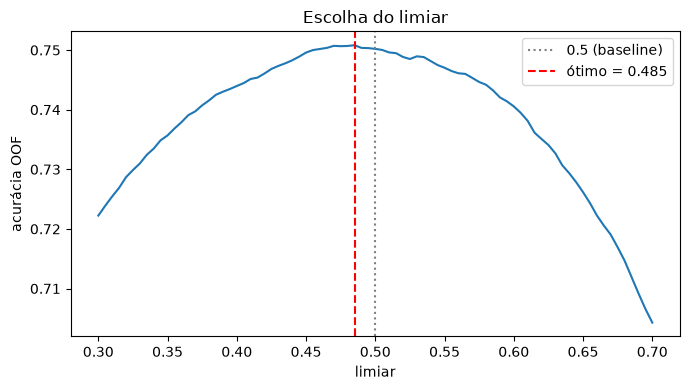

In [18]:
oof_m3 = O @ np.array(PESOS) / np.sum(PESOS)
limiares = np.arange(0.30, 0.701, 0.005)
acc_lim = [accuracy_score(y_train, (oof_m3 >= t).astype(int)) for t in limiares]
LIMIAR_OTIMO = float(limiares[int(np.argmax(acc_lim))])
print(f'limiar ótimo {LIMIAR_OTIMO:.3f} | acc OOF {max(acc_lim):.4f} (em 0.5 era {accuracy_score(y_train, (oof_m3 >= 0.5).astype(int)):.4f})')

plt.figure(figsize=(7, 4))
plt.plot(limiares, acc_lim)
plt.axvline(0.5, color='gray', ls=':', label='0.5 (baseline)')
plt.axvline(LIMIAR_OTIMO, color='red', ls='--', label=f'ótimo = {LIMIAR_OTIMO:.3f}')
plt.xlabel('limiar'); plt.ylabel('acurácia OOF'); plt.legend(); plt.title('Escolha do limiar')
plt.tight_layout(); plt.show()

historico['M4 - + limiar'] = metricas(y_test, p3, limiar=LIMIAR_OTIMO)

### Alternativa - stacking

No lugar da média, uma regressão logística aprende como juntar as probabilidades out-of-fold dos 3 modelos.

In [19]:
meta = LogisticRegression(random_state=SEED).fit(O, y_train)
p_stack = meta.predict_proba(P_te)[:, 1]
print('coeficientes (LR, RF, XGB):', meta.coef_.round(3))
historico['Stacking'] = metricas(y_test, p_stack)

coeficientes (LR, RF, XGB): [[0.314 0.726 4.146]]


## Comparação final

In [20]:
tab = pd.DataFrame(historico).T
tab['Δ Acurácia'] = tab['Acurácia'] - tab.loc['Baseline', 'Acurácia']
tab['Δ AUC'] = tab['ROC-AUC'] - tab.loc['Baseline', 'ROC-AUC']
tab.round(4)

,Acurácia,Precisão,Recall,F1,ROC-AUC,Δ Acurácia,Δ AUC
Baseline,0.7401,0.7265,0.7836,0.7540,0.8160,0.0000,0.0000
M1 - hiperparâmetros,0.7463,0.7310,0.7925,0.7605,0.8219,0.0062,0.0058
M2 - + features LR,0.7499,0.7349,0.7947,0.7636,0.8235,0.0098,0.0075
M3 - + pesos,0.7497,0.7326,0.7993,0.7645,0.8250,0.0096,0.0089
M4 - + limiar,0.7496,0.7272,0.8117,0.7671,0.8250,0.0095,0.0089
Stacking,0.7490,0.7357,0.7899,0.7618,0.8248,0.0089,0.0087


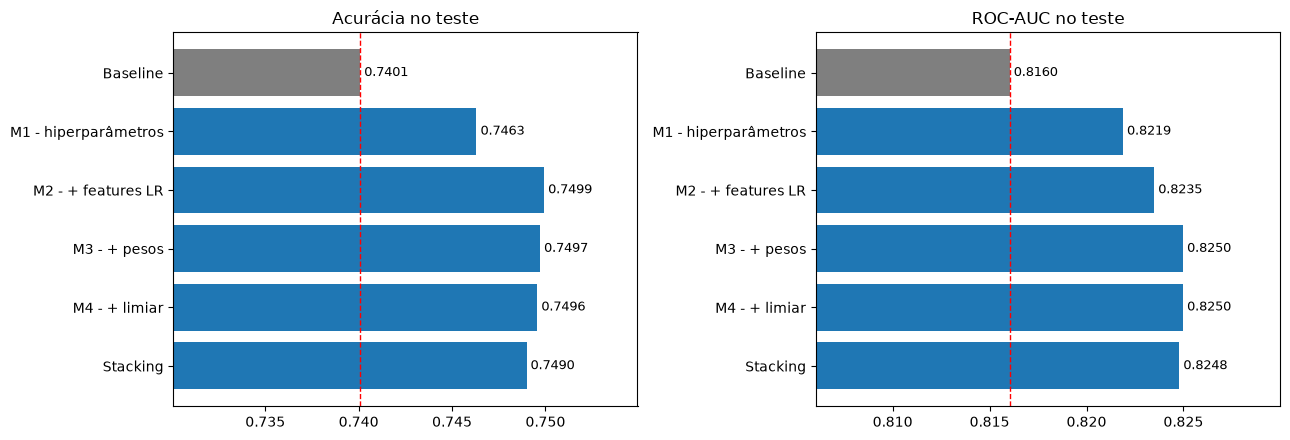

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, met in zip(ax, ['Acurácia', 'ROC-AUC']):
    v = tab[met]
    a.barh(v.index[::-1], v.values[::-1], color=['tab:blue'] * (len(v) - 1) + ['tab:gray'])
    a.set_xlim(v.min() - 0.01, v.max() + 0.005)
    a.axvline(v['Baseline'], color='red', ls='--', lw=1)
    for i, val in enumerate(v.values[::-1]):
        a.text(val, i, f' {val:.4f}', va='center', fontsize=9)
    a.set_title(met + ' no teste')
plt.tight_layout()
plt.savefig(f'{FIG}/comparacao_etapas.png', dpi=120)
plt.show()

## Conclusões

**O que melhorou de verdade foi M1 + M2: +0.98 p.p. de acurácia e +0.0075 de AUC em cima do baseline.**

- M1 foi o maior ganho, e quase tudo veio de **segurar a profundidade da random forest** (max_depth 9 em vez de
  ilimitado). O AUC dela foi de 0.7895 pra 0.8189 no teste. O XGBoost também ganhou com mais árvores e learning rate
  baixo. Com os três no mesmo nível, a média passa a somar em vez de diluir.
- No M2, o one-hot ajudou a regressão logística (CV 0.8191 → 0.8218). E a CV mostrou que o corte por correlação do
  baseline **piorava** os três modelos. Pearson só enxerga relação linear e de uma variável por vez: o Sex, por
  exemplo, quase não correlaciona com o alvo sozinho, mas ajuda junto com as outras. Por isso o final usa as 21 features.

**O que não valeu a pena: M3, M4 e stacking.**

- Os pesos ótimos deram (0.05, 0, 0.95), ou seja, o "ensemble" virou praticamente só o XGBoost. O AUC subiu 0.0015
  e a acurácia não mudou. O stacking mostra a mesma coisa: quase todo o peso vai pro XGBoost.
- O limiar ótimo deu 0.485, quase 0.5. Ele só troca precisão por recall (0.7993 → 0.8117) sem ganhar acurácia, o
  que faz sentido numa base 50/50. Mexer no limiar é mais uma decisão de negócio (quanto custa um falso negativo
  na triagem) do que ganho de modelo.
- Com 13.812 linhas no teste, o erro padrão da acurácia é uns 0.0037. Então as diferenças de 0.001 entre M2, M3, M4
  e stacking são ruído. Já o ganho de ~0.01 sobre o baseline passa de 2.5 erros padrão.

**Arquitetura final escolhida: M2**, soft voting com média simples, os três modelos otimizados, todas as features e
one-hot na regressão logística. Ela mantém a ideia da proposta (um modelo linear, um de bagging e um de boosting
votando juntos) e ganha quase 1 ponto de acurácia.

Pra ir além de ~0.75 de acurácia, acho que o caminho é ter dados melhores (glicemia, HbA1c), não um modelo mais
complexo. As variáveis aqui são autodeclaradas e bem grosseiras (faixa de idade, renda, saúde geral de 1 a 5).

## Anexo - tempo de execução

Só pra medir o tempo: o pipeline inteiro do baseline e da versão final (M2) numa célula só, começando do csv cru
(sem contar imports e download). A versão final é medida de dois jeitos:
- **completa**: com a busca de hiperparâmetros (Optuna) e a validação cruzada que decidiu as features
- **só treino**: usando os hiperparâmetros que a busca já achou (o que roda quando o modelo vai pra produção)

Nos dois casos os 3 modelos treinam em paralelo, igual no baseline.

In [22]:
import time

df_raw = pd.read_csv(path + '/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')  # leitura fora do cronômetro

def treinar_paralelo(mods, X_, y_):
    return dict(Parallel(n_jobs=3)(delayed(treinar)(n, m, X_, y_) for n, m in mods.items()))

# ---------------- BASELINE ----------------
t0 = time.perf_counter()
d = df_raw.drop_duplicates().reset_index(drop=True)
Xb, yb = d.drop(columns=ALVO), d[ALVO].astype(int)
Xtr_b, Xte_b, ytr_b, yte_b = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=SEED)
r = pd.concat([Xtr_b, ytr_b], axis=1).corr()[ALVO].drop(ALVO).abs().sort_values(ascending=False)  # mesma ordem do notebook
feats_b = r[r >= 0.05].index.tolist()
mods_b = treinar_paralelo({
    'LR': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    'RF': RandomForestClassifier(random_state=SEED, n_jobs=1),
    'XGB': XGBClassifier(random_state=SEED, n_jobs=1),
}, Xtr_b[feats_b], ytr_b)
proba_b, _ = soft_voting([m.predict_proba(Xte_b[feats_b])[:, 1] for m in mods_b.values()])
tempo_base = time.perf_counter() - t0
res_b = metricas(yte_b, proba_b)

# ---------------- VERSÃO FINAL (M2) COMPLETA, COM A BUSCA ----------------
t0 = time.perf_counter()
d = df_raw.drop_duplicates().reset_index(drop=True)
Xf, yf = d.drop(columns=ALVO), d[ALVO].astype(int)
Xtr_f, Xte_f, ytr_f, yte_f = train_test_split(Xf, yf, test_size=0.2, stratify=yf, random_state=SEED)
r = pd.concat([Xtr_f, ytr_f], axis=1).corr()[ALVO].drop(ALVO).abs().sort_values(ascending=False)  # mesma ordem do notebook
feats_f = r[r >= 0.05].index.tolist()
# busca de hiperparâmetros (mesma do M1)
blr, _ = otimizar(mk_lr, esp_lr, Xtr_f[feats_f], 10)
brf, _ = otimizar(mk_rf, esp_rf, Xtr_f[feats_f], 15)
bxgb, _ = otimizar(mk_xgb, esp_xgb, Xtr_f[feats_f], 30)
brf['n_estimators'] = 300
# decisão de features (mesma do M2)
todas = Xtr_f.columns.tolist()
s_sel = np.mean([cv_auc(mk_lr_oh(blr, feats_f), Xtr_f[feats_f]), cv_auc(mk_xgb(bxgb), Xtr_f[feats_f]), cv_auc(mk_rf(brf), Xtr_f[feats_f])])
s_all = np.mean([cv_auc(mk_lr_oh(blr, todas), Xtr_f), cv_auc(mk_xgb(bxgb), Xtr_f), cv_auc(mk_rf(brf), Xtr_f)])
cols = todas if s_all > s_sel else feats_f
mods_f = treinar_paralelo({'LR': mk_lr_oh(blr, cols), 'RF': mk_rf(brf), 'XGB': mk_xgb(bxgb)}, Xtr_f[cols], ytr_f)
proba_f, _ = soft_voting([m.predict_proba(Xte_f[cols])[:, 1] for m in mods_f.values()])
tempo_final_busca = time.perf_counter() - t0
res_f = metricas(yte_f, proba_f)

# ---------------- VERSÃO FINAL (M2) SÓ TREINO, HIPERPARÂMETROS JÁ CONHECIDOS ----------------
t0 = time.perf_counter()
d = df_raw.drop_duplicates().reset_index(drop=True)
Xf, yf = d.drop(columns=ALVO), d[ALVO].astype(int)
Xtr_f, Xte_f, ytr_f, yte_f = train_test_split(Xf, yf, test_size=0.2, stratify=yf, random_state=SEED)
cols = Xtr_f.columns.tolist()
mods_t = treinar_paralelo({'LR': mk_lr_oh(blr, cols), 'RF': mk_rf(brf), 'XGB': mk_xgb(bxgb)}, Xtr_f, ytr_f)
proba_t, _ = soft_voting([m.predict_proba(Xte_f)[:, 1] for m in mods_t.values()])
tempo_final_treino = time.perf_counter() - t0
res_t = metricas(yte_f, proba_t)

pd.DataFrame({
    'Tempo (s)': [tempo_base, tempo_final_busca, tempo_final_treino],
    'Acurácia': [res_b['Acurácia'], res_f['Acurácia'], res_t['Acurácia']],
    'ROC-AUC': [res_b['ROC-AUC'], res_f['ROC-AUC'], res_t['ROC-AUC']],
}, index=['Baseline', 'Final M2 (com busca)', 'Final M2 (só treino)']).round(4)

,Tempo (s),Acurácia,ROC-AUC
Baseline,8.9459,0.7401,0.8160
Final M2 (com busca),336.6436,0.7499,0.8235
Final M2 (só treino),8.9782,0.7499,0.8235
